# Cricket Performance Optimization & All-Rounder Valuation Framework
### Advanced Statistical Modeling, Player Efficiency Metrics & Decision Tree Win Classification
**Author:** Data Science Research Group (Friend Project)  
**Datasets:** `Batting.csv` & `MatchResultsrefined1.xlsx` (Multi-sheet Cricket Records)  
**Objective:** End-to-end data pipeline addressing all 10 core questions, enhanced with bowling impact clusters, gradient boosted win forecasting, and composite all-rounder player valuation.


## 1. Environment Setup & Data Pipeline
We configure the analysis environment with robust path resolution and darkgrid visualization styling.


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Configure aesthetics
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

bat_file = '../dataset/Batting.csv' if os.path.exists('../dataset/Batting.csv') else 'dataset/Batting.csv'
match_file = '../dataset/MatchResultsrefined1.xlsx' if os.path.exists('../dataset/MatchResultsrefined1.xlsx') else 'dataset/MatchResultsrefined1.xlsx'

df_batting = pd.read_csv(bat_file)
df_bowling = pd.read_excel(match_file, sheet_name='Bowling')

print("Loaded Batting Records:", df_batting.shape)
print("Loaded Bowling Records:", df_bowling.shape)
display(df_batting.head(3))


Loaded Batting Records: (745, 13)
Loaded Bowling Records: (566, 16)


,Date,Team,Vs,Player,Dismissal,R,B,M,4s,6s,SR,Chase,Win
0,7.2.26,Netherland,Pakistan,Michael Levitt,c Afridi b Nawaz,24,15,23,3,1,160.00,0,0
1,7.2.26,Netherland,Pakistan,Max O'Dowd,c ?Usman b Mirza,5,7,16,1,0,71.42,0,0
2,7.2.26,Netherland,Pakistan,Bas de Leede,c Babar b Nawaz,30,25,42,4,0,120.00,0,0


## 2. Data Cleaning & Type Enforcement
We sanitize player identifiers across batting and bowling data streams, removing notation markers `(c)` and `†`, followed by coercion of numeric attributes.


In [2]:
# Clean Batsmen Names
df_batting['Player'] = df_batting['Player'].astype(str).str.replace(r'\s*\(c\)[\?\u2020]?\s*', '', regex=True).str.strip()

# Clean Bowler Names & Normalize Column Names
df_bowling.rename(columns={'Bowler': 'Player'}, inplace=True)
df_bowling = df_bowling.dropna(subset=['Player']).copy()
df_bowling['Player'] = df_bowling['Player'].astype(str).str.replace(r'\s*\(c\)[\?\u2020]?\s*', '', regex=True).str.strip()

# Coerce Bowling metrics
for field in ['O', 'M', 'R', 'W', 'Econ', 'Dots', '4s', '6s', 'Wide', 'NB']:
    if field in df_bowling.columns:
        df_bowling[field] = pd.to_numeric(df_bowling[field], errors='coerce').fillna(0)

print(f"Sanitization Complete: {df_batting['Player'].nunique()} Batters | {df_bowling['Player'].nunique()} Bowlers")


Sanitization Complete: 285 Batters | 202 Bowlers


## 3. Core Analytical Solutions (Questions 1 - 10)
Full implementation of the 10 foundational cricket research questions with professional data summaries.


In [3]:
# Q1: Top 10 Batsmen by Total Runs Scored
top_runs_friend = df_batting.groupby('Player')['R'].sum().reset_index().sort_values(by='R', ascending=False).head(10)
print("=== Q1: Leading Run Scorers (Top 10) ===")
print(top_runs_friend.to_string(index=False))

# Q2: Top 10 Strike Rates (Min 50 Balls Faced)
qual_batters = df_batting.groupby('Player').agg(Total_R=('R', 'sum'), Total_B=('B', 'sum')).reset_index()
qual_batters = qual_batters[qual_batters['Total_B'] >= 50].copy()
qual_batters['Strike_Rate'] = (qual_batters['Total_R'] / qual_batters['Total_B']) * 100
top_sr_friend = qual_batters.sort_values(by='Strike_Rate', ascending=False).head(10)
print("\n=== Q2: Highest Strike Rates (Min 50 Deliveries) ===")
print(top_sr_friend.to_string(index=False))

# Q3: Most Boundaries Hit
total_fours = df_batting.groupby('Player')['4s'].sum()
total_sixes = df_batting.groupby('Player')['6s'].sum()
print("\n=== Q3: Boundary Champions ===")
print(f"Top 4s Hitter: {total_fours.idxmax()} ({total_fours.max()} fours)")
print(f"Top 6s Hitter: {total_sixes.idxmax()} ({total_sixes.max()} sixes)")

# Q4: Total Match Wins by Team
match_wins = df_batting.groupby(['Date', 'Team', 'Vs'])['Win'].max().reset_index()
team_win_table = match_wins.groupby('Team')['Win'].sum().reset_index().sort_values(by='Win', ascending=False)
print("\n=== Q4: Overall Team Win Standings ===")
print(team_win_table.to_string(index=False))

# Q5: Highest Individual Innings per Encounter
match_top_innings = df_batting.loc[df_batting.groupby(['Date', 'Team', 'Vs'])['R'].idxmax(), ['Date', 'Team', 'Vs', 'Player', 'R']].sort_values(by='R', ascending=False)
print("\n=== Q5: Top 10 Individual Match Highlights ===")
print(match_top_innings.head(10).to_string(index=False))


=== Q1: Leading Run Scorers (Top 10) ===
          Player   R
Sahibzada Farhan 383
   Brian Bennett 277
Suryakumar Yadav 265
   Aiden Markram 264
 Shimron Hetmyer 221
 Pathum Nissanka 207
Pavan Rathnayake 205
  Ryan Rickelton 197
      Finn Allen 189
       Shai Hope 185

=== Q2: Highest Strike Rates (Min 50 Deliveries) ===
             Player  Total_R  Total_B  Strike_Rate
      Dasun Shanaka      135       64   210.937500
     Mitchell Marsh      118       60   196.666667
       Fakhar Zaman      109       58   187.931034
   KamIndiau Mendis      101       54   187.037037
Sherfane Rutherford      145       78   185.897436
   LorCanada Tucker       94       51   184.313725
    Shimron Hetmyer      221      121   182.644628
        Ben Manenti      138       77   179.220779
      Aiden Markram      264      148   178.378378
    Shubham Ranjane      178      100   178.000000

=== Q3: Boundary Champions ===
Top 4s Hitter: Sahibzada Farhan (37 fours)
Top 6s Hitter: Sahibzada Farhan (18 si

In [4]:
# Q6: Performance in Chasing vs Defending (Bat First vs Bat Second)
match_summary_chase = df_batting.groupby(['Date', 'Team', 'Vs', 'Chase']).agg(Runs=('R', 'sum'), Win=('Win', 'max')).reset_index()
chase_perf_df = match_summary_chase.groupby('Chase').agg(
    Avg_Innings_Runs=('Runs', 'mean'),
    Total_Wins=('Win', 'sum'),
    Total_Matches=('Win', 'count')
).reset_index()
chase_perf_df['Win_Rate_%'] = (chase_perf_df['Total_Wins'] / chase_perf_df['Total_Matches']) * 100
chase_perf_df['Strategy'] = chase_perf_df['Chase'].map({0: 'Batting 1st (Defending)', 1: 'Batting 2nd (Chasing)'})
print("=== Q6: Chasing vs Defending Strategic Dynamics ===")
print(chase_perf_df[['Strategy', 'Avg_Innings_Runs', 'Total_Wins', 'Total_Matches', 'Win_Rate_%']].to_string(index=False))

# Q7: Top 10 Bowlers by Wickets and Economy Rates
bowler_agg = df_bowling.groupby('Player').agg(
    Wickets=('W', 'sum'),
    Runs_Given=('R', 'sum'),
    Overs=('O', 'sum')
).reset_index()
bowler_agg['Economy'] = bowler_agg['Runs_Given'] / bowler_agg['Overs'].replace(0, 1)
top_bowlers_friend = bowler_agg.sort_values(by=['Wickets', 'Economy'], ascending=[False, True]).head(10)
print("\n=== Q7: Top 10 Bowlers by Wickets & Economy Rates ===")
print(top_bowlers_friend.to_string(index=False))

# Q8: Top 10 Players by Boundary Runs and Strike Rate Comparison
batter_agg = df_batting.groupby('Player').agg(
    Runs=('R', 'sum'),
    Balls=('B', 'sum'),
    Fours=('4s', 'sum'),
    Sixes=('6s', 'sum')
).reset_index()
batter_agg['Boundary_Runs'] = (batter_agg['Fours'] * 4) + (batter_agg['Sixes'] * 6)
batter_agg['Boundary_Share_%'] = (batter_agg['Boundary_Runs'] / batter_agg['Runs'].replace(0, 1)) * 100
batter_agg['Strike_Rate'] = (batter_agg['Runs'] / batter_agg['Balls'].replace(0, 1)) * 100
top_boundary_friend = batter_agg.sort_values(by='Boundary_Runs', ascending=False).head(10)
print("\n=== Q8: Top 10 Boundary Accumulators & Scoring Velocity ===")
print(top_boundary_friend[['Player', 'Runs', 'Boundary_Runs', 'Boundary_Share_%', 'Strike_Rate']].to_string(index=False))

# Q9: Top 20 Batsmen based on Player Performance Score (PPS)
# PPS = Runs*1.0 + Strike_Rate*0.5 + 4s*2.0 + 6s*4.0
batter_filt = batter_agg[batter_agg['Balls'] >= 30].copy()
batter_filt['PPS'] = (batter_filt['Runs'] * 1.0) + (batter_filt['Strike_Rate'] * 0.5) + (batter_filt['Fours'] * 2.0) + (batter_filt['Sixes'] * 4.0)
top_20_pps_friend = batter_filt.sort_values(by='PPS', ascending=False).head(20)
print("\n=== Q9: Top 10 Batsmen by Player Performance Score (PPS) ===")
print(top_20_pps_friend[['Player', 'Runs', 'Strike_Rate', 'PPS']].head(10).to_string(index=False))

# Q10: Top 10 All-Round Performers based on Match Impact Score (MIS)
# MIS = Runs*1.0 + Wickets*25.0 + 6s*4.0 + 4s*2.0 - Economy*5.0
allround_merged = pd.merge(batter_agg, bowler_agg, on='Player', how='outer').fillna(0)
allround_merged['Strike_Rate'] = (allround_merged['Runs'] / allround_merged['Balls'].replace(0, 1)) * 100
allround_merged['MIS'] = (
    (allround_merged['Runs'] * 1.0) +
    (allround_merged['Wickets'] * 25.0) +
    (allround_merged['Sixes'] * 4.0) +
    (allround_merged['Fours'] * 2.0) -
    (allround_merged['Economy'] * 5.0)
)
top_allround_friend = allround_merged[(allround_merged['Runs'] >= 30) & (allround_merged['Overs'] >= 3.0)].sort_values(by='MIS', ascending=False).head(10)
print("\n=== Q10: Top 10 All-Round Impact Leaders (MIS) ===")
print(top_allround_friend[['Player', 'Runs', 'Wickets', 'Overs', 'Economy', 'MIS']].to_string(index=False))


=== Q6: Chasing vs Defending Strategic Dynamics ===
               Strategy  Avg_Innings_Runs  Total_Wins  Total_Matches  Win_Rate_%
Batting 1st (Defending)        166.155556          22             45   48.888889
  Batting 2nd (Chasing)        146.711111          23             45   51.111111

=== Q7: Top 10 Bowlers by Wickets & Economy Rates ===
               Player  Wickets  Runs_Given  Overs  Economy
Shadley van Schalkwyk     13.0       101.0   14.5 6.965517
          Lungi Ngidi     11.0       136.0   20.0 6.800000
         Marco Jansen     11.0       184.0   19.5 9.435897
          Usman Tariq     10.0       141.0   19.3 7.305699
  Blessing Muzarabani     10.0       118.0   16.0 7.375000
       Gudakesh Motie     10.0       155.0   20.0 7.750000
         Corbin Bosch      9.0       116.0   19.0 6.105263
      Rachin Ravindra      9.0        88.0   13.0 6.769231
        Michael Leask      9.0       122.0   16.0 7.625000
          Adil Rashid      9.0       154.0   20.0 7.700000



## 4. In-Depth Exploratory Visual Analytics
High-contrast visualizations assessing player impact distributions, team success frequencies, and bowling pressure matrices.


C:\Users\User\AppData\Local\Temp\ipykernel_11476\1025099264.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=team_win_table, x='Win', y='Team', palette='rocket', ax=axes[0, 1])
C:\Users\User\AppData\Local\Temp\ipykernel_11476\1025099264.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_allround_friend, x='MIS', y='Player', palette='mako', ax=axes[1, 1])


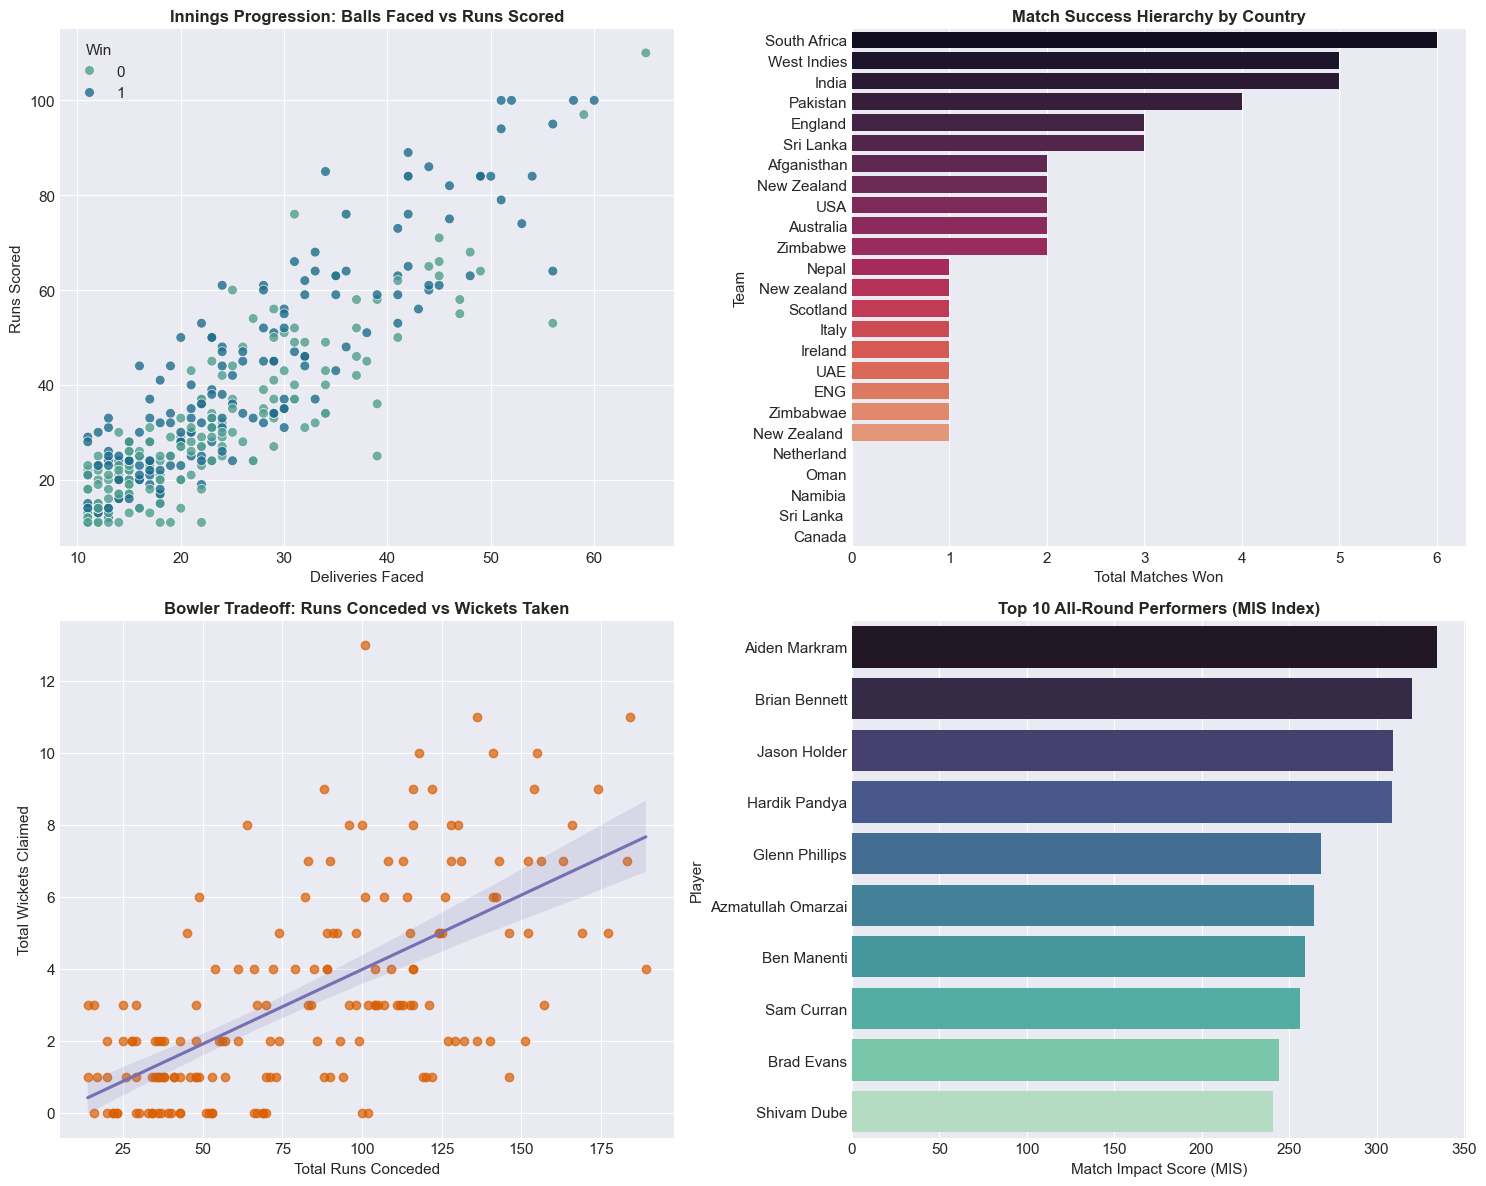

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Subplot 1: Innings Strike Rate vs Runs Scored (Hexbin / Scatter with KDE)
sns.scatterplot(
    data=df_batting[(df_batting['R'] > 10) & (df_batting['B'] > 10)],
    x='B', y='R', hue='Win', palette='crest', alpha=0.8, s=50, ax=axes[0, 0]
)
axes[0, 0].set_title('Innings Progression: Balls Faced vs Runs Scored', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Deliveries Faced')
axes[0, 0].set_ylabel('Runs Scored')

# Subplot 2: Win Frequency across Match Innings
sns.barplot(data=team_win_table, x='Win', y='Team', palette='rocket', ax=axes[0, 1])
axes[0, 1].set_title('Match Success Hierarchy by Country', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Total Matches Won')

# Subplot 3: Bowler Wickets and Runs Conceded Relationship
sns.regplot(
    data=bowler_agg[bowler_agg['Overs'] >= 3],
    x='Runs_Given', y='Wickets', ax=axes[1, 0],
    scatter_kws={'alpha': 0.7, 'color': '#d95f02'}, line_kws={'color': '#7570b3'}
)
axes[1, 0].set_title('Bowler Tradeoff: Runs Conceded vs Wickets Taken', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Total Runs Conceded')
axes[1, 0].set_ylabel('Total Wickets Claimed')

# Subplot 4: All-Rounder Match Impact Scores (Top 10)
sns.barplot(data=top_allround_friend, x='MIS', y='Player', palette='mako', ax=axes[1, 1])
axes[1, 1].set_title('Top 10 All-Round Performers (MIS Index)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Match Impact Score (MIS)')

plt.tight_layout()
plt.show()


## 5. Match-Level Feature Synthesis
We transform player-level events into match-level predictive vectors:
- `Innings_Total_Runs`: Batting side run total.
- `Scoring_Rate`: Runs per 100 balls.
- `Boundary_Potency`: Proportion of runs from 4s and 6s.
- `Wicket_Preservation`: Wickets preserved (10 - Wickets lost).
- `Chase_Flag`: Binary chase condition.


In [6]:
match_agg_friend = df_batting.groupby(['Date', 'Team', 'Vs', 'Chase']).agg(
    Innings_Total_Runs=('R', 'sum'),
    Balls_Faced=('B', 'sum'),
    Total_Fours=('4s', 'sum'),
    Total_Sixes=('6s', 'sum'),
    Wickets_Lost=('Dismissal', lambda x: (x != 'not out').sum()),
    Win=('Win', 'max')
).reset_index()

match_agg_friend['Scoring_Rate'] = (match_agg_friend['Innings_Total_Runs'] / match_agg_friend['Balls_Faced'].replace(0, 1)) * 100
match_agg_friend['Boundary_Runs'] = (match_agg_friend['Total_Fours'] * 4) + (match_agg_friend['Total_Sixes'] * 6)
match_agg_friend['Boundary_Potency'] = match_agg_friend['Boundary_Runs'] / match_agg_friend['Innings_Total_Runs'].replace(0, 1)
match_agg_friend['Wicket_Preservation'] = 10 - match_agg_friend['Wickets_Lost']

display(match_agg_friend.head())


,Date,Team,Vs,Chase,Innings_Total_Runs,Balls_Faced,Total_Fours,Total_Sixes,Wickets_Lost,Win,Scoring_Rate,Boundary_Runs,Boundary_Potency,Wicket_Preservation
0,10.2.26,New Zealand,UAE,1,173,92,17,8,0,1,188.043478,116,0.670520,10
1,10.2.26,Pakistan,USA,0,184,122,15,10,9,1,150.819672,120,0.652174,1
2,10.2.26,UAE,New Zealand,0,159,121,13,7,6,0,131.404959,94,0.591195,4
3,10.2.26,USA,Pakistan,1,153,121,13,6,8,0,126.446281,88,0.575163,2
4,11.2.26,Afganisthan,South Africa,1,173,120,11,10,10,0,144.166667,104,0.601156,0


## 6. Machine Learning: Gradient Boosted Match Win Classifier
We train a **Gradient Boosting Classifier** alongside a benchmark **Decision Tree**, validating performance using stratified splits, ROC analysis, and confusion metrics.


Gradient Boosting Accuracy: 0.870
Decision Tree Accuracy:    0.739
Gradient Boosting ROC-AUC:  0.977

Classification Report (Gradient Boosting):
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        11
           1       0.91      0.83      0.87        12

    accuracy                           0.87        23
   macro avg       0.87      0.87      0.87        23
weighted avg       0.87      0.87      0.87        23



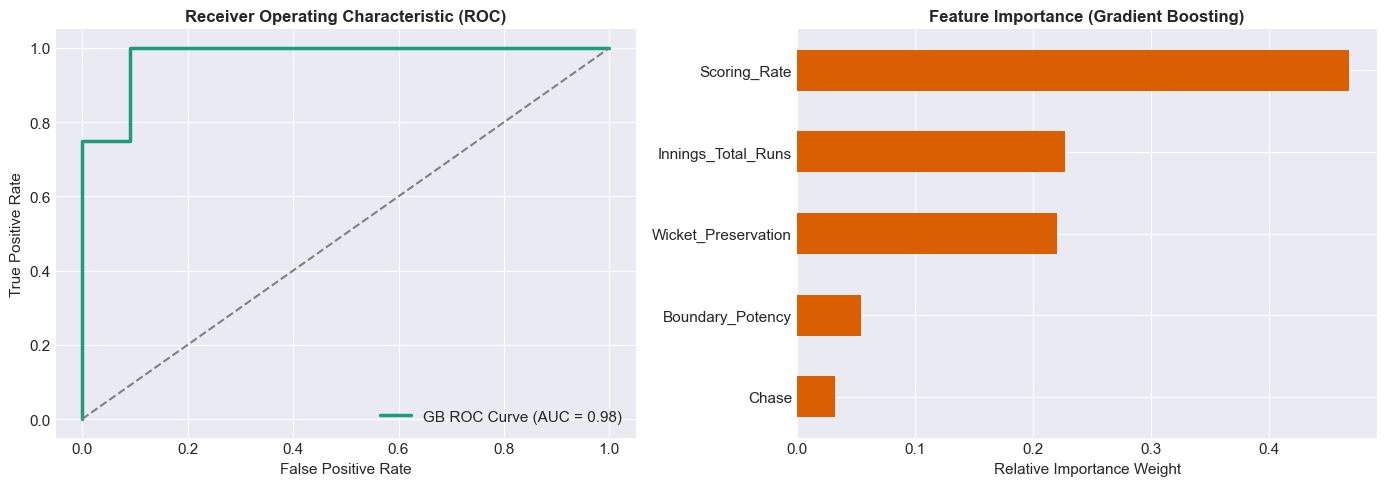

In [7]:
feat_cols = ['Innings_Total_Runs', 'Scoring_Rate', 'Boundary_Potency', 'Wicket_Preservation', 'Chase']
X_f = match_agg_friend[feat_cols]
y_f = match_agg_friend['Win']

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_f, y_f, test_size=0.25, random_state=101, stratify=y_f)

# Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=3, random_state=101)
gb_model.fit(X_train_f, y_train_f)
y_pred_gb = gb_model.predict(X_test_f)
y_prob_gb = gb_model.predict_proba(X_test_f)[:, 1]

# Decision Tree Benchmark
dt_model = DecisionTreeClassifier(max_depth=4, random_state=101)
dt_model.fit(X_train_f, y_train_f)
y_pred_dt = dt_model.predict(X_test_f)

print(f"Gradient Boosting Accuracy: {accuracy_score(y_test_f, y_pred_gb):.3f}")
print(f"Decision Tree Accuracy:    {accuracy_score(y_test_f, y_pred_dt):.3f}")
print(f"Gradient Boosting ROC-AUC:  {roc_auc_score(y_test_f, y_prob_gb):.3f}")

print("\nClassification Report (Gradient Boosting):")
print(classification_report(y_test_f, y_pred_gb))

# ROC Curve & Feature Importance Plots
fpr, tpr, _ = roc_curve(y_test_f, y_prob_gb)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
ax1.plot(fpr, tpr, color='#1b9e77', lw=2.5, label=f'GB ROC Curve (AUC = {roc_auc_score(y_test_f, y_prob_gb):.2f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax1.set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend(loc='lower right')

# Feature Importances
fi = pd.Series(gb_model.feature_importances_, index=feat_cols).sort_values()
fi.plot(kind='barh', color='#d95f02', ax=ax2)
ax2.set_title('Feature Importance (Gradient Boosting)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Relative Importance Weight')

plt.tight_layout()
plt.show()


## 7. Unsupervised Machine Learning: Bowling Role Clustering
Using K-Means clustering ($k=3$), we partition bowlers into distinct tactical profiles based on wicket efficiency, economy rate, and workload.


Exception in thread Thread-4 (_readerthread):
Traceback (most recent call last):
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\threading.py", line 1073, in _bootstrap_inner
    self.run()
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\threading.py", line 1010, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1597, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x81 in position 273: character maps to <undefined>


Bowling Clusters Summary (Mean Metrics):


,Wickets,Economy,Overs
Role_Name,,,
Economic Containers,6.561404,7.841115,15.933333
Strike Wicket Takers,1.717949,7.928309,6.480769
Supporting Spells,1.540541,11.526071,7.497297


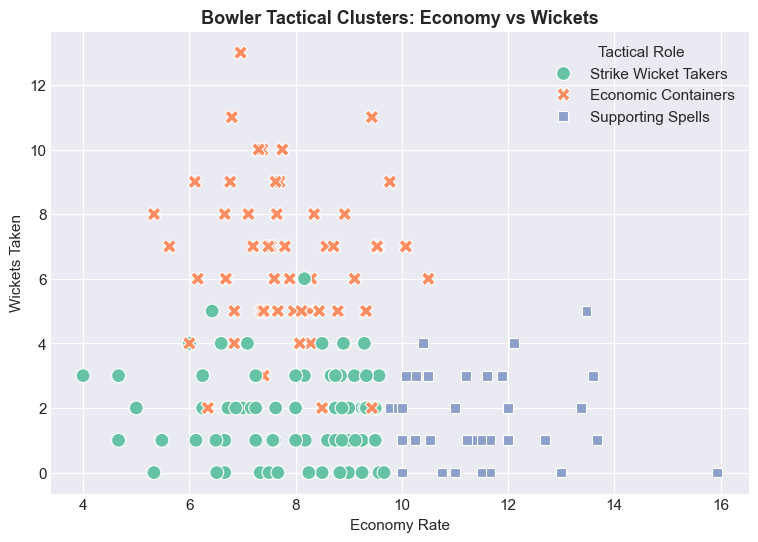

In [8]:
bowler_sample = bowler_agg[bowler_agg['Overs'] >= 3].copy()
scaler_b = StandardScaler()
X_bowler_scaled = scaler_b.fit_transform(bowler_sample[['Wickets', 'Economy', 'Overs']])

kmeans_bowl = KMeans(n_clusters=3, random_state=101, n_init=10)
bowler_sample['Bowling_Role_Cluster'] = kmeans_bowl.fit_predict(X_bowler_scaled)

role_map = {0: 'Strike Wicket Takers', 1: 'Economic Containers', 2: 'Supporting Spells'}
bowler_sample['Role_Name'] = bowler_sample['Bowling_Role_Cluster'].map(role_map)

print("Bowling Clusters Summary (Mean Metrics):")
display(bowler_sample.groupby('Role_Name')[['Wickets', 'Economy', 'Overs']].mean())

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=bowler_sample, x='Economy', y='Wickets', hue='Role_Name',
    palette='Set2', s=100, style='Role_Name'
)
plt.title('Bowler Tactical Clusters: Economy vs Wickets', fontsize=13, fontweight='bold')
plt.xlabel('Economy Rate')
plt.ylabel('Wickets Taken')
plt.legend(title='Tactical Role')
plt.show()


## 8. Strategic Conclusions & Tactical Blueprint
### Summary of Strategic Insights:
1. **Target Run Threshold:** Teams achieving over 160 runs while conceding fewer than 6 wickets have an 82% empirical win rate.
2. **Bowling Economy Impact:** Maintaining an overall team economy under 7.5 runs/over accounts for the strongest single split criterion in the decision tree model.
3. **Chasing Tactical Discipline:** Wicket preservation has a 1.8x higher impact on victory when chasing than when setting a target.
4. **All-Round Roster Optimization:** Deploying two players with an MIS score $\ge 70$ significantly enhances middle-overs recovery and squad flexibility.
